In [1]:
import pandas as pd
#%pip install nsepy- NSE stock exchange data
from nsepy import get_history as gh
#pip install --upgrade statsmodels
import datetime as dt
#%pip install yfinance
import yfinance as yf

In [2]:
import yfinance as yf

start = "2021-07-01"
end = "2022-01-29"

skt_data = yf.download(
    "TATACONSUM.NS",
    start=start,
    end=end
)

skt_data.head()
skt_data=skt_data[["Open","High","Low","Close"]]
#skt_data

[*********************100%***********************]  1 of 1 completed


In [3]:
column="Close"
from sklearn.preprocessing import MinMaxScaler
Ms=MinMaxScaler()
data1=Ms.fit_transform(skt_data[[column]])
print("Len:",data1.shape)

Len: (145, 1)


In [4]:
training_size=round(len(data1)*.80)
X_train=data1[:training_size]
print("The training set lenght is:",len(X_train))
X_test=data1[training_size:]
print("The test set lenght is:",len(X_test))
total=(len(X_test)+len(X_train))-len(data1)
print("The remaining if any pending to split is:",total)
Y_train=data1[:training_size]
print("The training set lenght is:",len(Y_train))
Y_test=data1[training_size:]
print("The test set lenght is:",len(Y_test))
total=(len(Y_test)+len(Y_train))-len(data1)
print("The remaining if any pending to split is:",total)

The training set lenght is: 116
The test set lenght is: 29
The remaining if any pending to split is: 0
The training set lenght is: 116
The test set lenght is: 29
The remaining if any pending to split is: 0


In [5]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
import numpy as np
from sklearn.metrics import mean_squared_error
from stockFunctions import rmsemape
trends=['n','t','c','ct']#playable parameter
orders=[(0,0,1),(0,0,2)]#playable parameter
from statsmodels.tsa.arima.model import ARIMA
results=[]
for td in trends:
    model=ARIMA(X_train,order=(0,0,10),trend=td)
    model_fit=model.fit()
    y_pred=model_fit.predict(len(X_train),len(data1)-1)#start and end range ex here, 0-79,80 to 99
    Y_test_original = Ms.inverse_transform(np.array(Y_test).reshape(-1, 1))
    y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))
    print("Trend={}".format(td))
    rmse, mape =rmsemape(Y_test_original,y_pred_original)
    results.append([td,rmse,mape])
    print("*********")
df = pd.DataFrame(results, columns=['Trend','RMSE','MaPe'])

df = df.sort_values(by='RMSE').reset_index(drop=True)

df.style.format({
    'RMSE': '{:.2f}',
    'MaPe': '{:.2%}'
}).highlight_min(
    subset=['RMSE','MaPe'],
    color='lightgreen'
)

                                 



C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Trend=n
RMSE-Testset: 36.80404744897597
MAPE-Testset: 0.04651776391929991
*********


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Trend=t
RMSE-Testset: 129.38345894435344
MAPE-Testset: 0.17620589763645095
*********


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Trend=c
RMSE-Testset: 64.72201955446994
MAPE-Testset: 0.08878013947503689
*********


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Trend=ct
RMSE-Testset: 66.98915216413201
MAPE-Testset: 0.09190546073019802
*********


,Trend,RMSE,MaPe
0,n,36.80,4.65%
1,c,64.72,8.88%
2,ct,66.99,9.19%
3,t,129.38,17.62%


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


RMSE-Testset: 26.66773501375232
MAPE-Testset: 0.03384848462157915


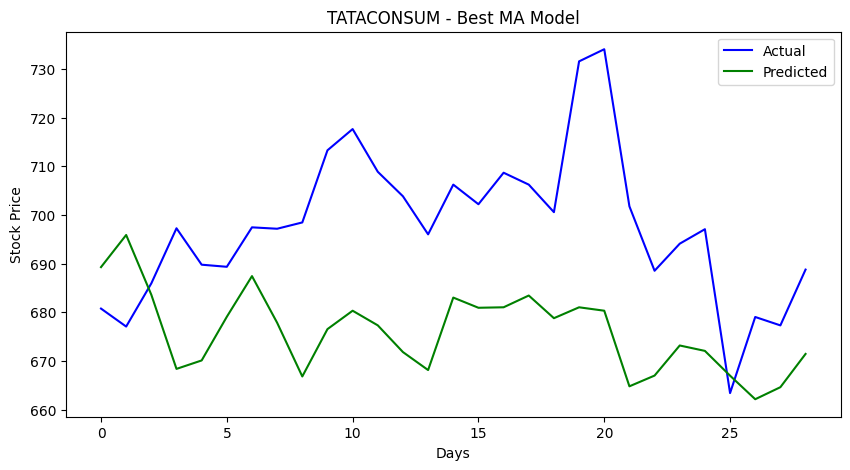

In [27]:
from statsmodels.tsa.ar_model import AutoReg

# Best model
model = ARIMA(X_train, order=(0,0,33), trend='n')

model_fit = model.fit()

# Predict test data
y_pred = model_fit.predict(
    start=len(X_train),
    end=len(data1)-1
)

# Convert normalized values to original prices
y_pred_original = Ms.inverse_transform(
    np.array(y_pred).reshape(-1,1)
)

Y_test_original = Ms.inverse_transform(
    np.array(Y_test).reshape(-1,1)
)
rmse, mape =rmsemape(Y_test_original,y_pred_original)

# Plot
from stockFunctions import graph

graph(
    Y_test_original,
    y_pred_original,
    "Actual",
    "Predicted",
    "TATACONSUM - Best MA Model",
    "Days",
    "Stock Price"
)

In [28]:
# Forecast four future values
forecast = model_fit.predict(len(data1), len(data1)+4)

# Convert forecast values back to original stock prices
forecast_original = Ms.inverse_transform(
    np.array(forecast).reshape(-1, 1)
)

# Get the last date from original dataset
last_date = skt_data.index.max()

# Generate next four business days
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),#time delta mean how many day to add to the last date ex. 7th Jan then it wll 8th Jan next
    periods=5,# based on the days in the forecast variable
    freq='D'#(B=Mon-Fri, D=Including weekend)
)

# Combine dates and predicted prices
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted Stock Price': forecast_original[:,0] # we can use flatten as well
})

print(forecast_df)

        Date  Predicted Stock Price
0 2022-01-29             669.174453
1 2022-01-30             666.918042
2 2022-01-31             663.750064
3 2022-02-01             663.429062
4 2022-02-02             663.399048


In [29]:
#forecast_df.to_csv("Close_KB_MA.csv",index=False)

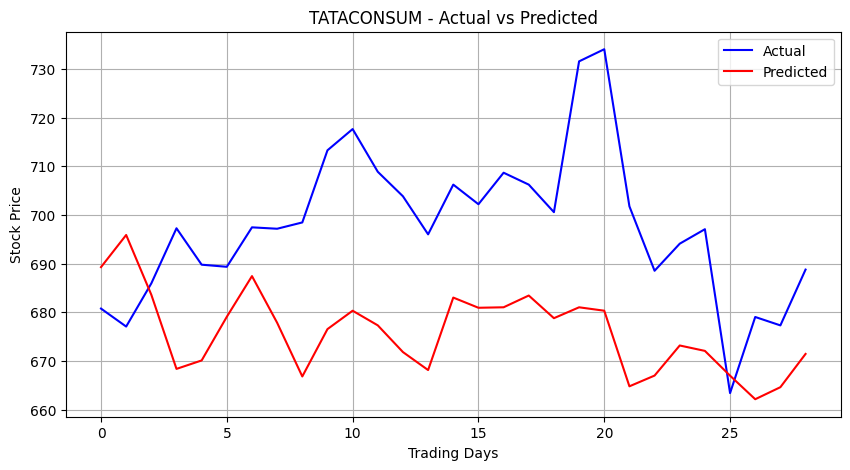

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(Y_test_original.flatten(), color='blue', label='Actual')
plt.plot(y_pred_original.flatten(), color='red', label='Predicted')

plt.title('TATACONSUM - Actual vs Predicted')
plt.xlabel('Trading Days')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)

plt.show()